Features: momentum and volatility

Build raw (not normalized) momentum and volatility features at each decision date.
Inputs are `data/processed/panel.csv` and `data/processed/labels.csv` (only for the decision dates).
Output is `data/processed/features_raw.csv`.

## Setup

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# src is one folder up from notebooks, so add that folder so the import works
sys.path.append("..")
from src.data import load_data
from src.labels import make_month_end_prices
from src.features import make_wide, make_market_return, make_momentum_features, make_daily_window_features

PANEL_PATH = "../data/processed/panel.csv"
LABELS_PATH = "../data/processed/labels.csv"
FEATURES_PATH = "../data/processed/features_raw.csv"

## 1. Load panel and labels, get decision dates

In [2]:
panel = load_data(PANEL_PATH)
labels = pd.read_csv(LABELS_PATH, parse_dates=["Date"])

# decision dates come from labels so features and labels share the same grid
decision_dates = pd.DatetimeIndex(sorted(labels["Date"].unique()), name="Date")

print("panel shape:", panel.shape)
print("number of decision dates:", len(decision_dates))
print("first decision date:", decision_dates[0].date())
print("last decision date:", decision_dates[-1].date())

panel shape: (57300, 17)
number of decision dates: 92
first decision date: 2019-01-31
last decision date: 2026-08-31


## 2. Daily returns (wide) and equal-weight market

In [3]:
# Daily_Return was checked on day 1 to match Adj_Close pct_change
daily_returns_wide = make_wide(panel, "Daily_Return")
market_return = make_market_return(daily_returns_wide)

print("daily returns shape (days, tickers):", daily_returns_wide.shape)
print()
print("first rows (first 4 tickers):")
print(daily_returns_wide.iloc[:5, :4])
print()
print("first rows of market return:")
print(market_return.head())

daily returns shape (days, tickers): (1910, 30)

first rows (first 4 tickers):
Ticker      ASHOKLEY.NS  ASIANPAINT.NS  AUROPHARMA.NS  AXISBANK.NS
Date                                                              
2019-01-01          NaN            NaN            NaN          NaN
2019-01-02    -0.024878       0.008567      -0.012003    -0.011557
2019-01-03    -0.018009       0.003615      -0.011666    -0.019515
2019-01-04    -0.013754      -0.001765       0.013898     0.019163
2019-01-07    -0.034607       0.007324      -0.001515     0.028809

first rows of market return:
Date
2019-01-01         NaN
2019-01-02   -0.008861
2019-01-03   -0.009977
2019-01-04    0.001898
2019-01-07    0.003442
Name: market_return, dtype: float64


## 3. Momentum features

In [4]:
month_end_prices = make_month_end_prices(panel, decision_dates)
momentum_features = make_momentum_features(month_end_prices)

# show all four momentum features for one ticker side by side
example_ticker = "INFY.NS"
example_momentum = pd.DataFrame()
for name in momentum_features:
    example_momentum[name] = momentum_features[name][example_ticker]

print("momentum features for", example_ticker)
print(example_momentum.head(15))

momentum features for INFY.NS
              mom_1m   mom_6_1  mom_12_1     chmom
Date                                              
2019-01-31       NaN       NaN       NaN       NaN
2019-02-28 -0.020345       NaN       NaN       NaN
2019-03-28  0.004766       NaN       NaN       NaN
2019-04-30  0.018366       NaN       NaN       NaN
2019-05-31 -0.018101       NaN       NaN       NaN
2019-06-28  0.006222       NaN       NaN       NaN
2019-07-31  0.084221 -0.009618       NaN       NaN
2019-08-30  0.026775  0.096093       NaN       NaN
2019-09-30 -0.011351  0.120102       NaN       NaN
2019-10-31 -0.138298  0.087417       NaN       NaN
2019-11-29  0.015680 -0.045697       NaN       NaN
2019-12-31  0.049975 -0.036728       NaN       NaN
2020-01-31  0.061273 -0.067154  0.001684 -0.057535
2020-02-28 -0.057027 -0.035811  0.085138 -0.131905
2020-03-31 -0.123275 -0.080357  0.018402 -0.200459


## 4. Daily-window features sampled at decision dates

In [5]:
daily_window_features = make_daily_window_features(daily_returns_wide, market_return, decision_dates)

# check the shape of each one, should all be (decision dates, tickers)
for name in daily_window_features:
    print(name, "shape:", daily_window_features[name].shape)

retvol_21d shape: (92, 30)
retvol_63d shape: (92, 30)
maxret_21d shape: (92, 30)
beta_252d shape: (92, 30)
idiovol_252d shape: (92, 30)


## 5. Combine all features into one long table

In [6]:
# put momentum and daily-window features in one dictionary
all_features = {}
for name in momentum_features:
    all_features[name] = momentum_features[name]
for name in daily_window_features:
    all_features[name] = daily_window_features[name]

features = None
for name in all_features:
    # wide (one column per ticker) to long (one row per Date, Ticker)
    one_feature_long = all_features[name].reset_index().melt(id_vars="Date", var_name="Ticker", value_name=name)

    if features is None:
        features = one_feature_long
    else:
        features = pd.merge(features, one_feature_long, on=["Date", "Ticker"])

features = features.sort_values(["Ticker", "Date"])
features = features.reset_index(drop=True)

print("features shape:", features.shape, "(expected", len(decision_dates) * 30, "rows)")
print()
print(features.head())

features shape:

 (2760, 11) (expected 2760 rows)

        Date       Ticker    mom_1m  mom_6_1  mom_12_1  chmom  retvol_21d  \
0 2019-01-31  ASHOKLEY.NS       NaN      NaN       NaN    NaN    0.016043   
1 2019-02-28  ASHOKLEY.NS  0.063960      NaN       NaN    NaN    0.026344   
2 2019-03-28  ASHOKLEY.NS  0.024277      NaN       NaN    NaN    0.018893   
3 2019-04-30  ASHOKLEY.NS -0.018623      NaN       NaN    NaN    0.020572   
4 2019-05-31  ASHOKLEY.NS  0.021852      NaN       NaN    NaN    0.022646   

   retvol_63d  maxret_21d  beta_252d  idiovol_252d  
0         NaN    0.015046        NaN           NaN  
1         NaN    0.062992        NaN           NaN  
2         NaN    0.045035        NaN           NaN  
3    0.022362    0.051003        NaN           NaN  
4    0.020345    0.055712        NaN           NaN  


## 6. NaNs per feature per year

In [7]:
feature_columns = list(all_features.keys())

# count missing values in each feature, grouped by year
year = features["Date"].dt.year
nans_per_year = features[feature_columns].isna().groupby(year).sum()

print("number of nans per feature per year (should only be in 2019 warm-up):")
print(nans_per_year)

number of nans per feature per year (should only be in 2019 warm-up):
      mom_1m  mom_6_1  mom_12_1  chmom  retvol_21d  retvol_63d  maxret_21d  \
Date                                                                         
2019      30      180       360    360           0          90           0   
2020       0        0         0      0           0           0           0   
2021       0        0         0      0           0           0           0   
2022       0        0         0      0           0           0           0   
2023       0        0         0      0           0           0           0   
2024       0        0         0      0           0           0           0   
2025       0        0         0      0           0           0           0   
2026       0        0         0      0           0           0           0   

      beta_252d  idiovol_252d  
Date                           
2019        360           360  
2020          0             0  
2021          0      

## 7. Leakage spot check: mom_12_1 and retvol_21d by hand

In [8]:
check_ticker = "INFY.NS"
check_date = pd.Timestamp("2023-06-30")

# only keep this stock's rows up to and including the decision date
one_stock = panel[panel["Ticker"] == check_ticker]
past_only = one_stock[one_stock["Date"] <= check_date]

# t-1 is the last trading day of may 2023, t-12 is the last trading day of june 2022
in_may_2023 = (past_only["Date"].dt.year == 2023) & (past_only["Date"].dt.month == 5)
in_june_2022 = (past_only["Date"].dt.year == 2022) & (past_only["Date"].dt.month == 6)
price_t_minus_1 = past_only[in_may_2023]["Adj_Close"].iloc[-1]
price_t_minus_12 = past_only[in_june_2022]["Adj_Close"].iloc[-1]
mom_12_1_by_hand = price_t_minus_1 / price_t_minus_12 - 1

# std of the last 21 daily returns up to the decision date
last_21_returns = past_only["Daily_Return"].iloc[-21:]
retvol_21d_by_hand = last_21_returns.std()

# values from the features table
feature_row = features[(features["Ticker"] == check_ticker) & (features["Date"] == check_date)]
mom_12_1_from_table = feature_row["mom_12_1"].iloc[0]
retvol_21d_from_table = feature_row["retvol_21d"].iloc[0]

print("ticker:", check_ticker, "decision date:", check_date.date())
print("latest date used by hand:", past_only["Date"].max().date())
print()
print("mom_12_1 by hand:    ", round(mom_12_1_by_hand, 6))
print("mom_12_1 from table: ", round(mom_12_1_from_table, 6))
print("match:", abs(mom_12_1_by_hand - mom_12_1_from_table) < 1e-12)
print()
print("retvol_21d by hand:    ", round(retvol_21d_by_hand, 6))
print("retvol_21d from table: ", round(retvol_21d_from_table, 6))
print("match:", abs(retvol_21d_by_hand - retvol_21d_from_table) < 1e-12)

ticker:

 INFY.NS decision date: 2023-06-30
latest date used by hand: 2023-06-30

mom_12_1 by hand:     -0.088373
mom_12_1 from table:  -0.088373
match: True

retvol_21d by hand:     0.012152
retvol_21d from table:  0.012152
match: True


## 8. Correlation between features

feature correlation matrix:
              mom_1m  mom_6_1  mom_12_1  chmom  retvol_21d  retvol_63d  \
mom_1m          1.00    -0.03     -0.03  -0.01       -0.02        0.06   
mom_6_1        -0.03     1.00      0.63   0.71       -0.05       -0.08   
mom_12_1       -0.03     0.63      1.00  -0.04       -0.02       -0.03   
chmom          -0.01     0.71     -0.04   1.00       -0.02       -0.04   
retvol_21d     -0.02    -0.05     -0.02  -0.02        1.00        0.81   
retvol_63d      0.06    -0.08     -0.03  -0.04        0.81        1.00   
maxret_21d      0.33    -0.05     -0.03  -0.01        0.82        0.67   
beta_252d       0.02     0.07      0.13  -0.02        0.31        0.37   
idiovol_252d    0.12     0.18      0.15   0.09        0.51        0.66   

              maxret_21d  beta_252d  idiovol_252d  
mom_1m              0.33       0.02          0.12  
mom_6_1            -0.05       0.07          0.18  
mom_12_1           -0.03       0.13          0.15  
chmom              -0.0

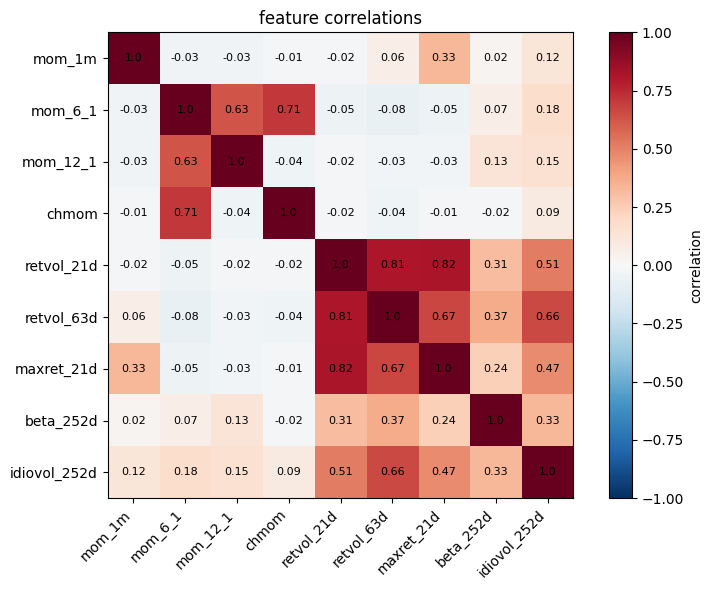

In [9]:
# pooled over all dates and tickers, rows with any nan are skipped pairwise
feature_corr = features[feature_columns].corr()

print("feature correlation matrix:")
print(feature_corr.round(2))

plt.figure(figsize=(8, 6))
plt.imshow(feature_corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xticks(range(len(feature_columns)), feature_columns, rotation=45, ha="right")
plt.yticks(range(len(feature_columns)), feature_columns)

# write the number inside each square
for row in range(len(feature_columns)):
    for col in range(len(feature_columns)):
        value = feature_corr.iloc[row, col]
        plt.text(col, row, round(value, 2), ha="center", va="center", fontsize=8)

plt.title("feature correlations")
plt.tight_layout()
plt.show()

## 9. Save raw features

In [10]:
features.to_csv(FEATURES_PATH, index=False)

print("saved features to", FEATURES_PATH)
print("rows:", len(features), "columns:", list(features.columns))

saved features to ../data/processed/features_raw.csv
rows: 2760 columns: ['Date', 'Ticker', 'mom_1m', 'mom_6_1', 'mom_12_1', 'chmom', 'retvol_21d', 'retvol_63d', 'maxret_21d', 'beta_252d', 'idiovol_252d']
